In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from utilz.plotting_utilz import *

In [2]:
self_results_dir = "../model_align_results/self_alignment/"
cross_results_dir = "../model_align_results/cross_alignment/"
figures_dir = "./paper_figs_v3/"


## Fig 1 - RSA similarity of projected reps to base reps 

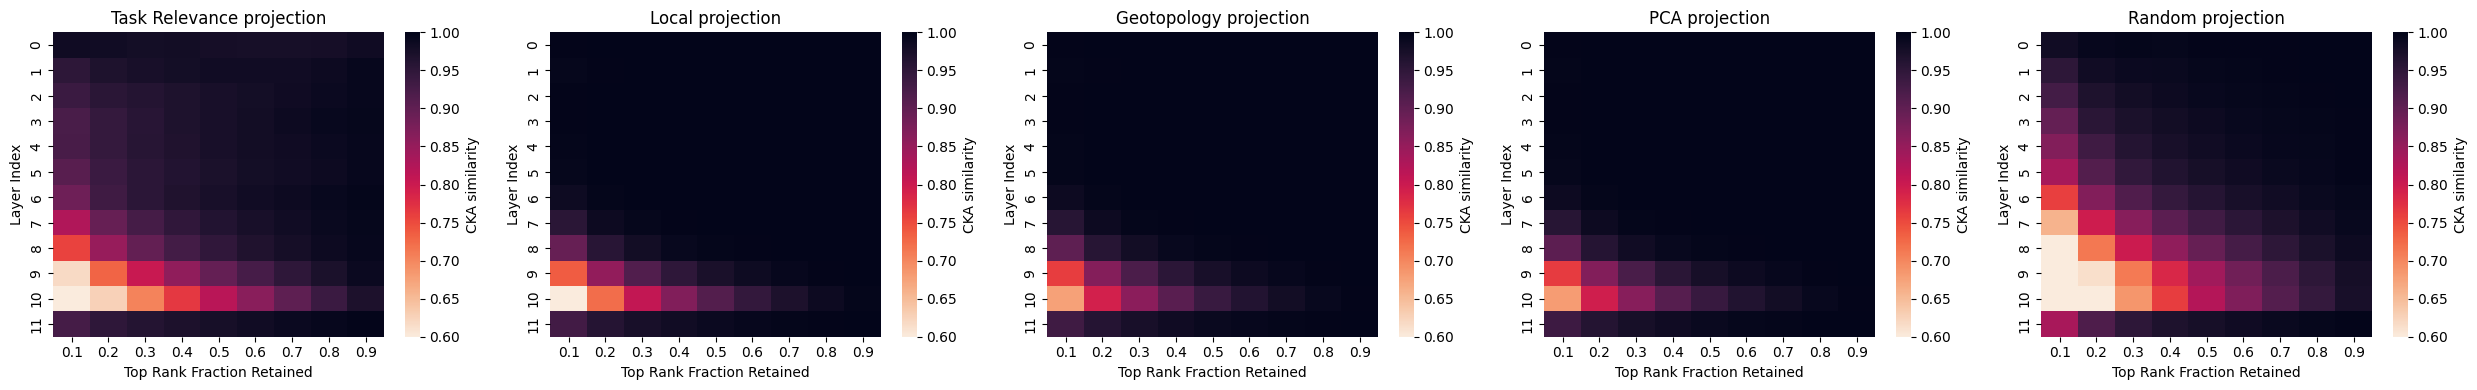

In [4]:
MODEL_NAME = 'vit_b_16'
METRIC = 'cka'
RENORM = True

proj_full_names = list(proj_to_shorthand.keys())
ANNOT = False
projs_to_plot = proj_full_names
proj_c_lims = [0.6, 1]
null_c_lims = [0, 1]
fig, axes = plt.subplots(1, len(projs_to_plot), figsize=(25, 4))


for pi, proj_name in enumerate(projs_to_plot):
    ax = axes[pi]
    res_df = pd.read_csv(f"{self_results_dir}/{MODEL_NAME}/self_align_layerwise.csv", index_col=0)

    res_df = res_df[res_df['compression_type'] == proj_name]
    res = extract_layer_rank_grid(res_df, null_proj=False, metric=METRIC, renorm=RENORM, avg_repeats=True if proj_name == 'random' else False)

    
    rank_fracs = extract_rank_fracs_from_data(res_df)
    layer_inds = extract_layer_inds_from_data(res_df)

    sns.heatmap(res, xticklabels=rank_fracs, yticklabels=layer_inds, ax=ax, 
            cmap='rocket_r', cbar_kws={'label': 'CKA similarity'}, vmin=proj_c_lims[0], vmax=proj_c_lims[1])
    ax.set_title(f"{proj_to_title[proj_name]} projection")
    
    ax.set_ylabel("Layer Index")
    ax.set_xlabel("Top Rank Fraction Retained")

    # annotate each cell with the CKA value
    for i in range(res.shape[0]):
        for j in range(res.shape[1]):
            
        #     if res[i,j] < proj_c_lims[0]: 
        #         ax.text(j+0.5, i+0.5, f"{res[i,j]:.3f}", ha='center', va='center', color='black', fontsize=7)

            if res[i,j] < 1 and res[i,j] > 0.95 and ANNOT:  
                ax.text(j+0.5, i+0.5, f"{res[i,j]:.3f}", ha='center', va='center', color='white', fontsize=6)
    
plt.tight_layout()
plt.show()

In [5]:
res_df = pd.read_csv(f"{self_results_dir}/{MODEL_NAME}/self_align_layerwise.csv", index_col=0)
res_df

,compression_type,repeat_iter,layer_idx,rank,retain_fraction_layer,rsa_renorm,cka_renorm,null_rsa_renorm,null_cka_renorm,norm_rep_distance,null_norm_rep_distance,n_eval_samples,n_ch_samples
0,task_relevance,0,0,77,0.100260,0.985999,0.984365,0.999242,0.999070,1.034492,0.479116,2000,2000
1,task_relevance,0,0,154,0.200521,0.983197,0.982624,0.998108,0.997833,0.947863,0.575314,2000,2000
2,task_relevance,0,0,230,0.299479,0.979646,0.979643,0.995947,0.995527,0.899335,0.627496,2000,2000
3,task_relevance,0,0,307,0.399740,0.979845,0.979795,0.993763,0.993046,0.842070,0.687566,2000,2000
4,task_relevance,0,0,384,0.500000,0.977790,0.977482,0.989259,0.987660,0.761788,0.769181,2000,2000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
751,random,2,11,384,0.500000,0.987563,0.978069,0.983024,0.971773,0.746343,0.784901,2000,2000
752,random,2,11,461,0.600260,0.991023,0.984378,0.976599,0.960881,0.661586,0.867323,2000,2000
753,random,2,11,538,0.700521,0.994491,0.990166,0.961450,0.935872,0.554269,0.967462,2000,2000
754,random,2,11,614,0.799479,0.996567,0.993891,0.940214,0.904141,0.451607,1.058930,2000,2000


In [3]:
proj_to_title['task'] = 'Task Sensitive'

In [ ]:
proj_colors.append('grey')


[(0.9677975592919913, 0.44127456009157356, 0.5358103155058701),
 (0.5920891529639701, 0.6418467016378244, 0.1935069134991043),
 (0.21044753832183283, 0.6773105080456748, 0.6433941168468681),
 (0.6423044349219739, 0.5497680051256467, 0.9582651433656727)]

In [11]:

projs_to_plot

['task_relevance', 'local_geometry', 'geotopology', 'pca', 'random']

In [13]:
proj_to_title['task_relevance'] = 'Task Sensitive'

task_relevance
local_geometry
geotopology
pca
random


/tmp/ipykernel_1992765/2362443723.py:56: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(np.round(ax.get_yticks(), 2), fontsize=12)
/tmp/ipykernel_1992765/2362443723.py:56: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(np.round(ax.get_yticks(), 2), fontsize=12)
/tmp/ipykernel_1992765/2362443723.py:56: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(np.round(ax.get_yticks(), 2), fontsize=12)
/tmp/ipykernel_1992765/2362443723.py:56: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(np.round(ax.get_yticks(), 2), fontsize=12)


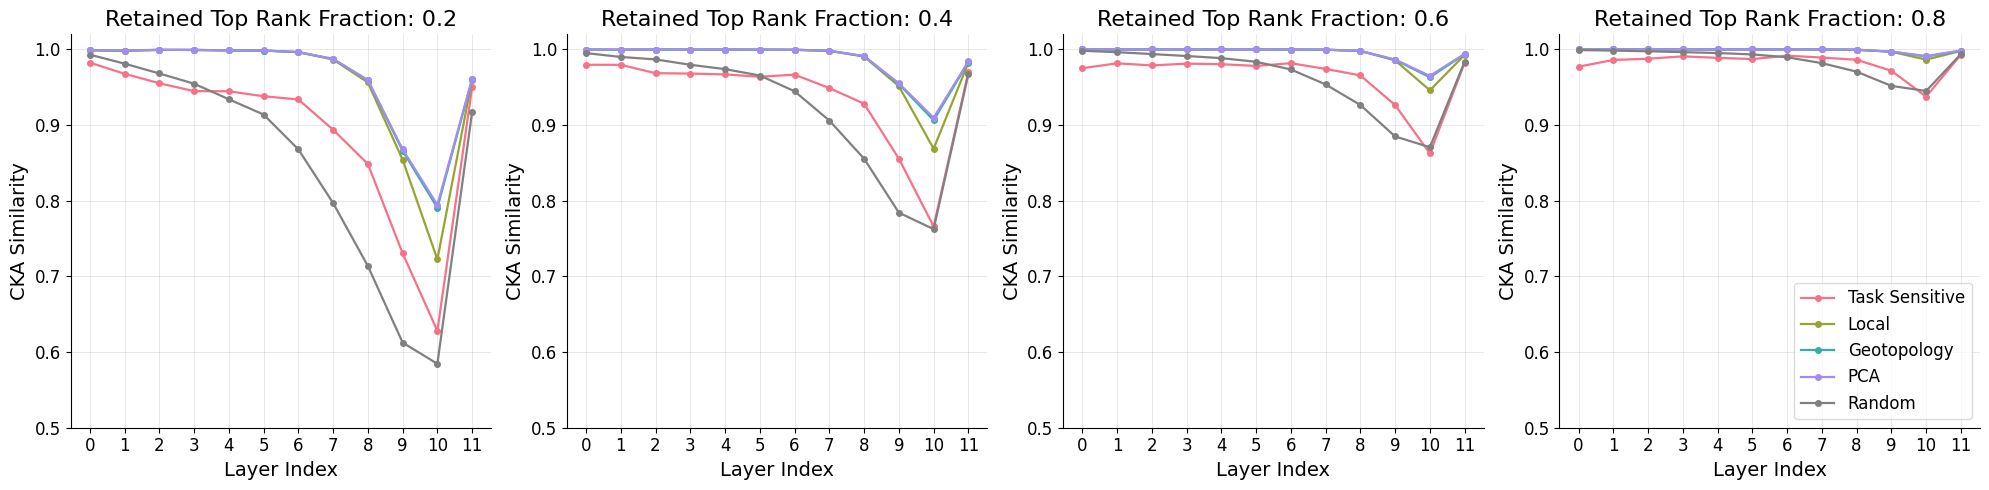

In [19]:
FIXED_RANK_FRACS = [0.2, 0.4, 0.6, 0.8]
MODEL_NAME = 'vit_b_16'
METRIC = 'cka'
RENORM = True


fig, axes = plt.subplots(1, len(FIXED_RANK_FRACS), figsize=(20, 5))
proj_full_names = list(proj_to_shorthand.keys())
ANNOT = False
projs_to_plot = proj_full_names

# preload all data
all_res = {}
for proj_name in projs_to_plot:
    print(proj_name)
    res_df = pd.read_csv(f"{self_results_dir}/{MODEL_NAME}/self_align_layerwise.csv", index_col=0)
    res_df = res_df[res_df['compression_type'] == proj_name]

    res = extract_layer_rank_grid(
        res_df, null_proj=False, metric=METRIC, renorm=RENORM,
        avg_repeats=True if proj_name == 'random' else False
    )
    
    rank_fracs = extract_rank_fracs_from_data(res_df)
    layer_inds = extract_layer_inds_from_data(res_df)
    
    all_res[proj_name] = {'grid': res, 'rank_fracs': rank_fracs, 'layer_inds': layer_inds}

for ai, r_frac in enumerate(FIXED_RANK_FRACS):
    ax = axes[ai]
    for proj_name in projs_to_plot:
        res        = all_res[proj_name]['grid']
        rank_fracs = all_res[proj_name]['rank_fracs']
        layer_inds = all_res[proj_name]['layer_inds']

        # find closest rank frac column
        rank_fracs_arr = np.array(rank_fracs)
        col_idx = np.argmin(np.abs(rank_fracs_arr - r_frac))

        cka_vals = res[:, col_idx]  # [n_layers]

        ax.plot(
            layer_inds, cka_vals,
            marker='o', markersize=4,
            linewidth=1.6,
            label=proj_to_title[proj_name],
            color=proj_colors[projs_to_plot.index(proj_name)],
        )

    ax.set_title(f"Retained Top Rank Fraction: {r_frac}", fontsize=16)
    ax.set_xlabel("Layer Index", fontsize=14)
    ax.set_ylabel(f"CKA Similarity", fontsize=14)
    ax.set_ylim(0.5, 1.02)
    ax.set_xticks(layer_inds)
    ax.set_xticklabels(layer_inds, fontsize=12)
    ax.set_yticklabels(np.round(ax.get_yticks(), 2), fontsize=12)
    ax.grid(True, linewidth=0.5, alpha=0.4)
    ax.spines[['top', 'right']].set_visible(False)

axes[-1].legend(loc='lower right', fontsize=12, framealpha=0.7)
plt.tight_layout()
plt.savefig(f"{figures_dir}/main/C1_{MODEL_NAME}_base_self_align_layerwise.png", dpi=300)
plt.show()

## Fig 2 - Cross Reps Alignment between Same Projections




In [20]:
result_df = pd.read_csv(os.path.join(cross_results_dir, f"{MODEL_NAME}/cross_compression_alignment.csv"))
result_df

,m1_comp_type,m1_layer_idx,m1_rank,m1_retain_fraction_layer,m2_comp_type,m2_layer_idx,m2_rank,m2_retain_fraction_layer,rsa_renorm,cka_renorm,mean_principal_angle_deg,grassmann_distance,mean_cosine_similarity,n_eval_samples
0,task,0,77,0.100260,task,0,154,0.200521,0.997525,0.996960,NaN,NaN,NaN,2000
1,task,0,77,0.100260,task,0,230,0.299479,0.994829,0.993673,NaN,NaN,NaN,2000
2,task,0,77,0.100260,task,0,307,0.399740,0.993169,0.991048,NaN,NaN,NaN,2000
3,task,0,77,0.100260,task,0,384,0.500000,0.990925,0.988719,NaN,NaN,NaN,2000
4,task,0,77,0.100260,task,0,461,0.600260,0.987627,0.984825,NaN,NaN,NaN,2000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17167,random_seed1,11,461,0.600260,random_seed1,11,614,0.799479,0.993580,0.966809,NaN,NaN,NaN,2000
17168,random_seed1,11,461,0.600260,random_seed1,11,691,0.899740,0.991436,0.955489,NaN,NaN,NaN,2000
17169,random_seed1,11,538,0.700521,random_seed1,11,614,0.799479,0.997052,0.985016,NaN,NaN,NaN,2000
17170,random_seed1,11,538,0.700521,random_seed1,11,691,0.899740,0.994893,0.973501,NaN,NaN,NaN,2000


In [21]:
result_df['m1_comp_type'].unique(), result_df['m2_comp_type'].unique()

(<StringArray>
 ['task', 'pca', 'local', 'gt', 'random_seed0', 'random_seed1']
 Length: 6, dtype: str,
 <StringArray>
 ['task', 'pca', 'local', 'gt', 'random_seed0', 'random_seed1']
 Length: 6, dtype: str)

/tmp/ipykernel_1992765/2980042678.py:60: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


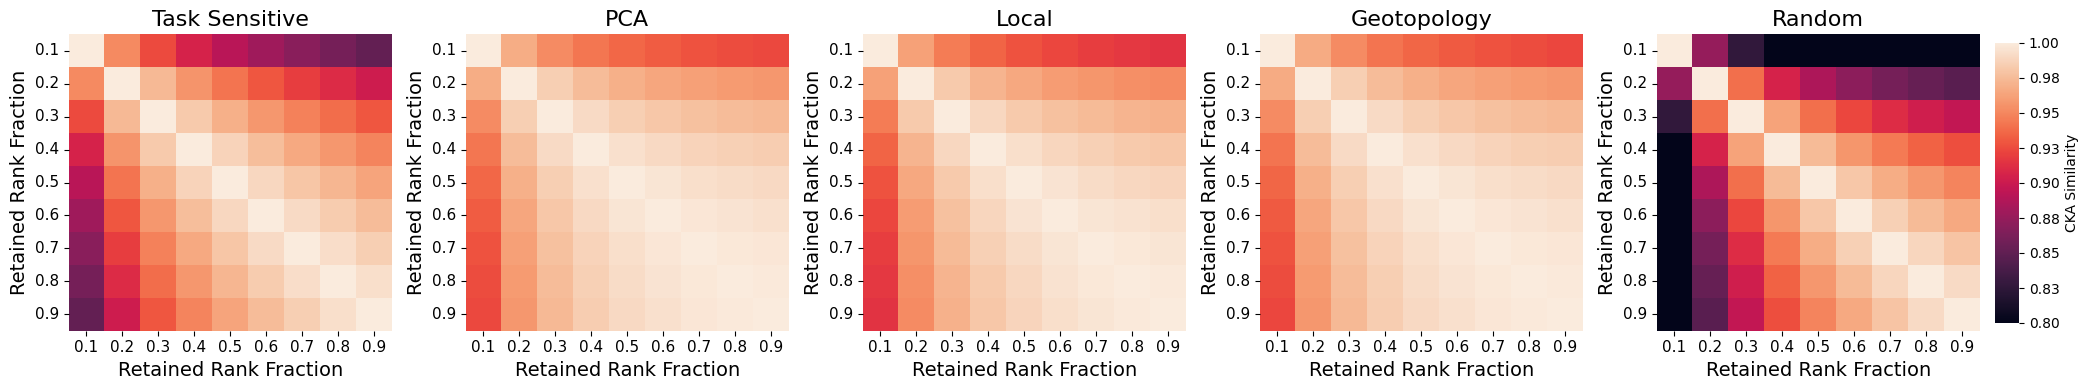

In [25]:
proj_types_to_plot = proj_types_with_random
fig, axes = plt.subplots(1, len(proj_types_to_plot), figsize=(20, 4))
fig.subplots_adjust(right=0.85)  # leave room on the right
cbar_ax = fig.add_axes([1, 0.18, 0.012, 0.7])
clim=[0.8,1.0]
# round m1 and m2 retain fracs to 2 decimals
result_df['m1_retain_fraction_layer'] = result_df['m1_retain_fraction_layer'].round(2)
result_df['m2_retain_fraction_layer'] = result_df['m2_retain_fraction_layer'].round(2)
rank_fracs = np.round(list(result_df['m1_retain_fraction_layer'].unique()), 2)
 # [left, bottom, width, height]


for ci, comp in enumerate(proj_types_to_plot):
    if comp != 'random':
        comp_df = result_df[(result_df['m1_comp_type'] == comp) & (result_df['m2_comp_type'] == comp)]
        same_layer_df = comp_df[comp_df["m1_layer_idx"] == comp_df["m2_layer_idx"]]

        rank_avg_alignment = same_layer_df.groupby(
            ["m1_retain_fraction_layer", "m2_retain_fraction_layer"]
        )["cka_renorm"].mean().unstack()
    
    else:
        random_grids = []
        for rep_i in range(2):
            r_comp = f"random_seed{rep_i}"
            comp_df = result_df[(result_df['m1_comp_type'] == r_comp) & (result_df['m2_comp_type'] == r_comp)]
            grid = comp_df.groupby(
                ["m1_retain_fraction_layer", "m2_retain_fraction_layer"]
            )["cka_renorm"].mean().unstack()
            random_grids.append(grid)

        rank_avg_alignment = sum(random_grids) / len(random_grids)

    # fill in lower triangle with upper values to make it symmetric
    rank_avg_alignment = rank_avg_alignment.combine_first(rank_avg_alignment.T)
    rank_avg_alignment = rank_avg_alignment.sort_index(axis=0).sort_index(axis=1)
    for idx in rank_avg_alignment.index:
        if idx in rank_avg_alignment.columns:
            rank_avg_alignment.loc[idx, idx] = 1.0


    sns.heatmap(
        rank_avg_alignment, ax=axes[ci],
        cmap="rocket", vmin=clim[0], vmax=clim[1],
        cbar=ci == len(proj_types_to_plot) - 1,  # only last gets cbar
        cbar_ax=cbar_ax if ci == len(proj_types_to_plot) - 1 else None,
        cbar_kws={'label': 'CKA Similarity', 'format': '%.2f'},
    )


    axes[ci].set_xlabel(r"Retained Rank Fraction", fontsize=14)
    axes[ci].set_ylabel(r"Retained Rank Fraction", fontsize=14)
    
    axes[ci].tick_params(axis='x', labelrotation=0, labelsize=11)
    axes[ci].tick_params(axis='y', labelrotation=0, labelsize=11)

    axes[ci].set_title(f"{proj_to_title[comp]}", fontsize=16)

# plt.suptitle(f"Representation Alignment between projections of same compression types\nModel: {MODEL_NAME}, Averaged across matching layers")
plt.tight_layout()
plt.savefig(f"{figures_dir}/main/C2_cross_same_compression_alignment_heatmap.png", dpi=300)

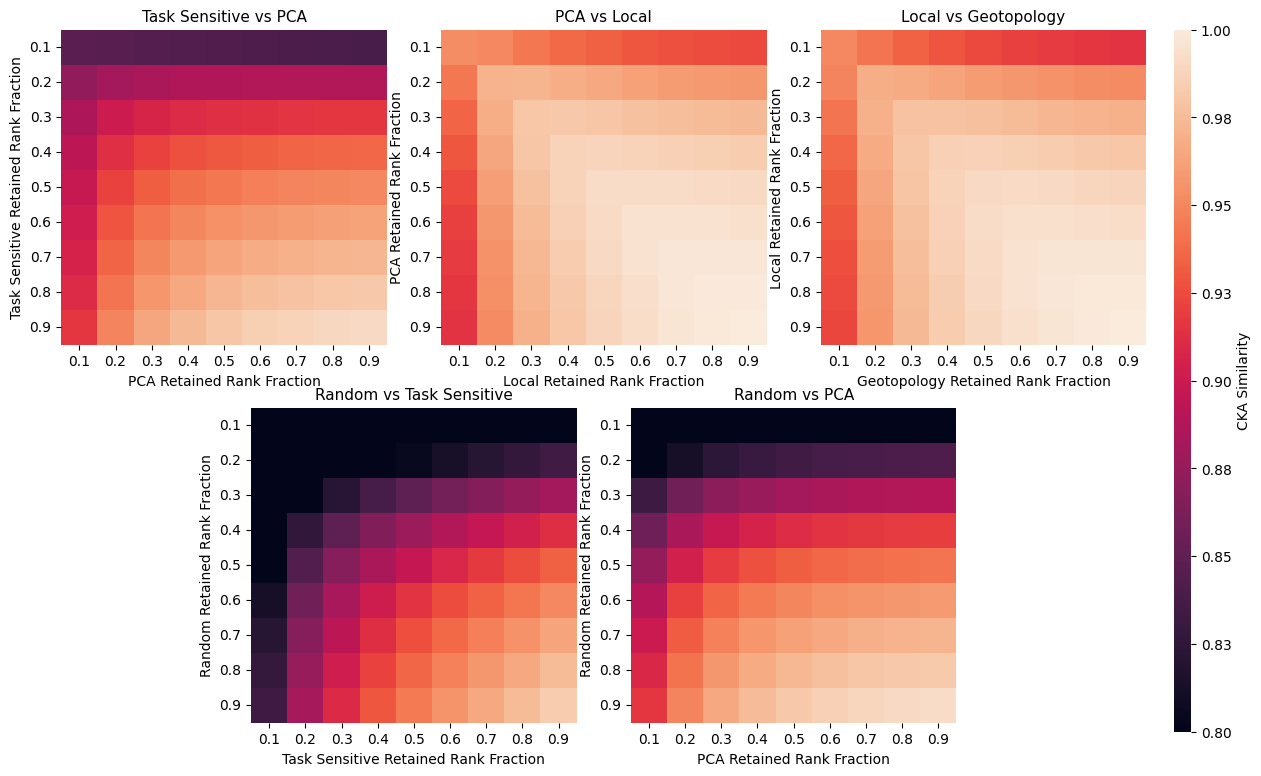

In [32]:
CROSS_PAIRS = [
    ("task", "pca"),
    ("pca",            "local"),
    ("local", "gt"),
    ("random",         "task"),
    ("random",         "pca"),
]
ROW1 = CROSS_PAIRS[:3]
ROW2 = CROSS_PAIRS[3:]
clim = [0.8, 1.0]

result_df['m1_retain_fraction_layer'] = result_df['m1_retain_fraction_layer'].round(1)
result_df['m2_retain_fraction_layer'] = result_df['m2_retain_fraction_layer'].round(1)

# expand random seeds into individual comp type strings
def expand_comp(ct):
    return [f"random_seed{i}" for i in range(2)] if ct == "random" else [ct]

def get_cross_pivot(ct1, ct2):
    ct1_list = expand_comp(ct1)
    ct2_list = expand_comp(ct2)
    chunks = []
    for c1 in ct1_list:
        for c2 in ct2_list:
            sub_fwd = result_df[
                (result_df["m1_comp_type"] == c1) &
                (result_df["m2_comp_type"] == c2) &
                (result_df["m1_layer_idx"] == result_df["m2_layer_idx"])
            ]
            sub_bwd = result_df[
                (result_df["m1_comp_type"] == c2) &
                (result_df["m2_comp_type"] == c1) &
                (result_df["m1_layer_idx"] == result_df["m2_layer_idx"])
            ].rename(columns={
                "m1_retain_fraction_layer": "m2_retain_fraction_layer",
                "m2_retain_fraction_layer": "m1_retain_fraction_layer",
            })
            chunks.append(sub_fwd)
            chunks.append(sub_bwd)
    sub = pd.concat(chunks, ignore_index=True)
    pivot = sub.groupby(
        ["m1_retain_fraction_layer", "m2_retain_fraction_layer"]
    )["cka_renorm"].mean().unstack()
    pivot = pivot.sort_index(axis=0).sort_index(axis=1)
    return pivot


fig = plt.figure(figsize=(14, 9))
gs = fig.add_gridspec(2, 6, hspace=0.2, wspace=0.4)
axes_row1 = [fig.add_subplot(gs[0, i*2:(i*2)+2]) for i in range(3)]
axes_row2 = [fig.add_subplot(gs[1, 1:3]), fig.add_subplot(gs[1, 3:5])]
all_axes  = axes_row1 + axes_row2

cbar_ax = fig.add_axes([0.92, 0.1, 0.012, 0.78])

for ai, (ax, (ct1, ct2)) in enumerate(zip(all_axes, CROSS_PAIRS)):
    is_last = ai == len(all_axes) - 1
    pivot = get_cross_pivot(ct1, ct2)

    sns.heatmap(
        pivot, ax=ax,
        cmap="rocket", vmin=clim[0], vmax=clim[1],
        cbar=is_last,
        cbar_ax=cbar_ax if is_last else None,
        cbar_kws={'label': 'CKA Similarity', 'format': '%.2f'},
        annot=False,
    )
    ax.set_title(f"{proj_to_title[ct1]} vs {proj_to_title[ct2]}", fontsize=11)
    ax.set_xlabel(rf"{proj_to_title[ct2]} Retained Rank Fraction", fontsize=10)
    ax.set_ylabel(rf"{proj_to_title[ct1]} Retained Rank Fraction", fontsize=10)
    ax.tick_params(axis='x', labelrotation=0, labelsize=10)
    ax.tick_params(axis='y', labelrotation=0, labelsize=10)

fig.subplots_adjust(right=0.90)
plt.savefig(f"{figures_dir}/main/C3_cross_projection_alignment_heatmap.png", dpi=300)
# plt.tight_layout()
plt.show()

In [92]:
print(result_df['m1_comp_type'].unique())
print(result_df['m2_comp_type'].unique())

<StringArray>
['task', 'pca', 'local', 'gt', 'random_seed0', 'random_seed1']
Length: 6, dtype: str
<StringArray>
['task', 'pca', 'local', 'gt', 'random_seed0', 'random_seed1']
Length: 6, dtype: str


## Fig 3 - Cross Reps Alignment between different Projections

# Supplementary

## Reps Distance to base reps

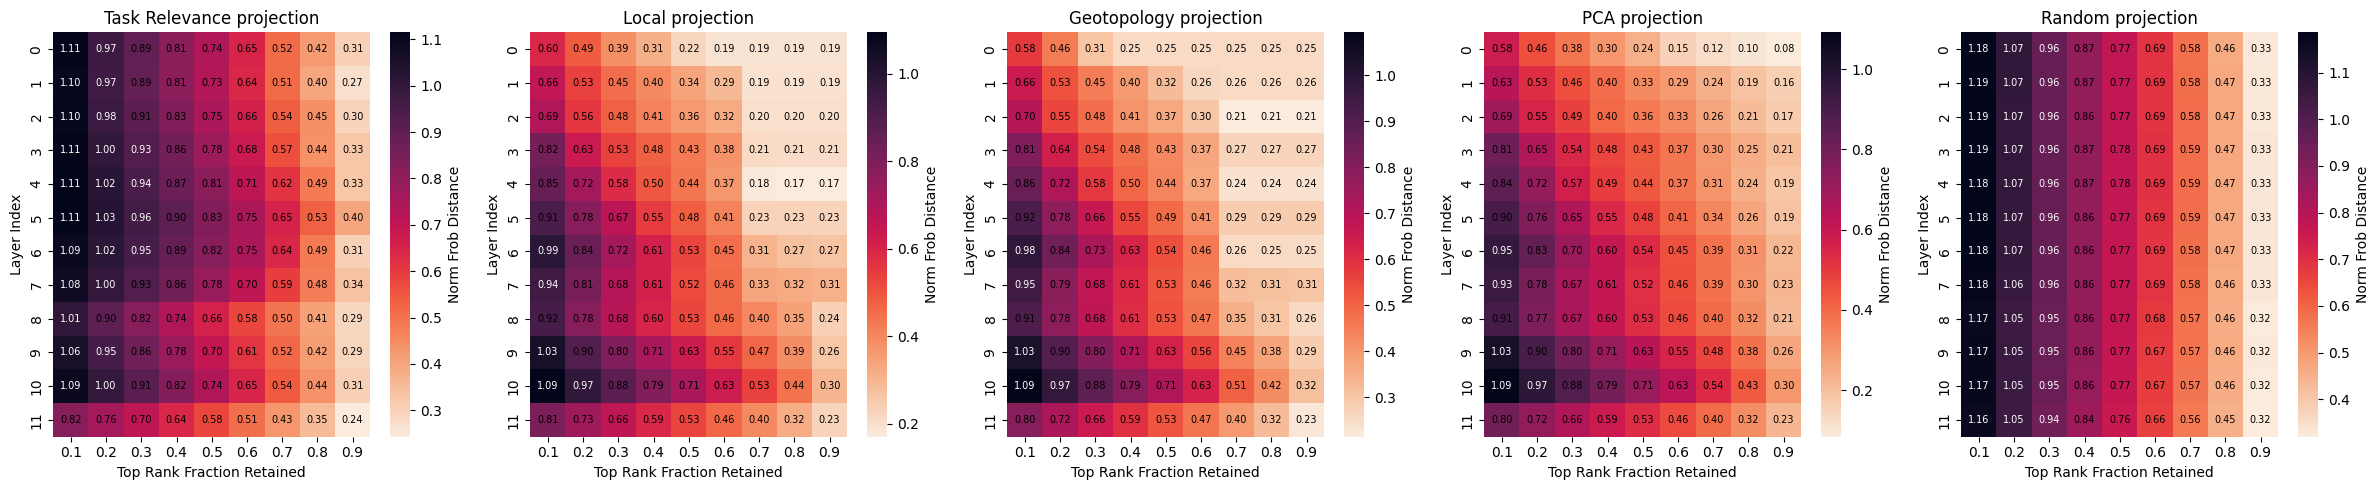

In [ ]:
MODEL_NAME = 'vit_b_16'
METRIC = 'norm_rep_distance'
RENORM = None

proj_full_names = list(proj_to_shorthand.keys()) + ['random']
proj_to_title['random'] = 'Random'
ANNOT = True
fig, axes = plt.subplots(1, len(proj_full_names), figsize=(24, 5))

# proj_c_lims = [0, 1]
# null_c_lims = [0, 1]
for pi, proj_name in enumerate(proj_full_names):
    ax = axes[pi]
    res_df = pd.read_csv(f"{self_results_dir}/{MODEL_NAME}/self_align_layerwise.csv", index_col=0)
    res_df = res_df[res_df['compression_type'] == proj_name]
    res = extract_layer_rank_grid(res_df, null_proj=False, metric=METRIC, renorm=RENORM, avg_repeats=True if proj_name == 'random' else False)
    rank_fracs = extract_rank_fracs_from_data(res_df)
    layer_inds = extract_layer_inds_from_data(res_df)

    sns.heatmap(res, xticklabels=rank_fracs, yticklabels=layer_inds, ax=ax, 
            cmap='rocket_r', cbar_kws={'label': 'Norm Frob Distance'})
    ax.set_title(f"{proj_to_title[proj_name]} projection")

    if ANNOT:
        for i in range(res.shape[0]):
            for j in range(res.shape[1]):
                color = 'white' if res[i,j] > 0.93 else 'black'
                ax.text(j+0.5, i+0.5, f"{res[i,j]:.2f}", ha='center', va='center', color=color, fontsize=7)
    
    ax.set_ylabel("Layer Index")
    ax.set_xlabel("Top Rank Fraction Retained")



plt.tight_layout()
plt.savefig(f"{figures_dir}/supp/fig_SC1_{MODEL_NAME}_{METRIC}_base_rep_distance_layerwise_heatmaps_with_random.png", dpi=300)
plt.show()